# Predicting Superconducting Critical Temperature Using Machine Learning

This notebook contains the code required to reproduce the data split, model fitting, evaluation, and plot generation for predicting the critical temperatures of superconducting materials using the UCI Superconductivity dataset. The notebook examines ordinary least squares (OLS) linear regression, Ridge regression, and XGBoost, a nonlinear gradient-boosted decision-tree model. The final test-set comparison focuses on OLS and XGBoost.

# 1. Data Quality, Inspection, and Exploratory Data Analysis

In [91]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from xgboost import XGBRegressor

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.model_selection import ParameterSampler

This notebook requires the train.csv and unique_m.csv files from the UCI Superconductivity dataset. Place both files in the project repository directory before running the notebook. See the README for instructions on obtaining the dataset.

In [4]:
DATA_DIR = Path.cwd()

if not (DATA_DIR / "train.csv").exists():
    DATA_DIR = DATA_DIR.parent

train = pd.read_csv(DATA_DIR / "train.csv")
unique_m = pd.read_csv(DATA_DIR / "unique_m.csv")

print("train.csv:", train.shape)
print("unique_m.csv:", unique_m.shape)

display(train.head())
display(unique_m.head())

train.csv: (21263, 82)
unique_m.csv: (21263, 88)


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


,H,He,Li,Be,B,C,N,O,F,Ne,...,Au,Hg,Tl,Pb,Bi,Po,At,Rn,critical_temp,material
0,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,29.0,Ba0.2La1.8Cu1O4
1,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,26.0,Ba0.1La1.9Ag0.1Cu0.9O4
2,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,19.0,Ba0.1La1.9Cu1O4
3,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,22.0,Ba0.15La1.85Cu1O4
4,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,23.0,Ba0.3La1.7Cu1O4


In [5]:
train.info()
unique_m.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21263 entries, 0 to 21262
Data columns (total 82 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   number_of_elements               21263 non-null  int64  
 1   mean_atomic_mass                 21263 non-null  float64
 2   wtd_mean_atomic_mass             21263 non-null  float64
 3   gmean_atomic_mass                21263 non-null  float64
 4   wtd_gmean_atomic_mass            21263 non-null  float64
 5   entropy_atomic_mass              21263 non-null  float64
 6   wtd_entropy_atomic_mass          21263 non-null  float64
 7   range_atomic_mass                21263 non-null  float64
 8   wtd_range_atomic_mass            21263 non-null  float64
 9   std_atomic_mass                  21263 non-null  float64
 10  wtd_std_atomic_mass              21263 non-null  float64
 11  mean_fie                         21263 non-null  float64
 12  wtd_mean_fie      

In [6]:
Tc_col = train["critical_temp"]
print(Tc_col.describe())

count    21263.000000
mean        34.421219
std         34.254362
min          0.000210
25%          5.365000
50%         20.000000
75%         63.000000
max        185.000000
Name: critical_temp, dtype: float64


In [7]:
print("Skewness:", Tc_col.skew())

Skewness: 0.8602232926106779


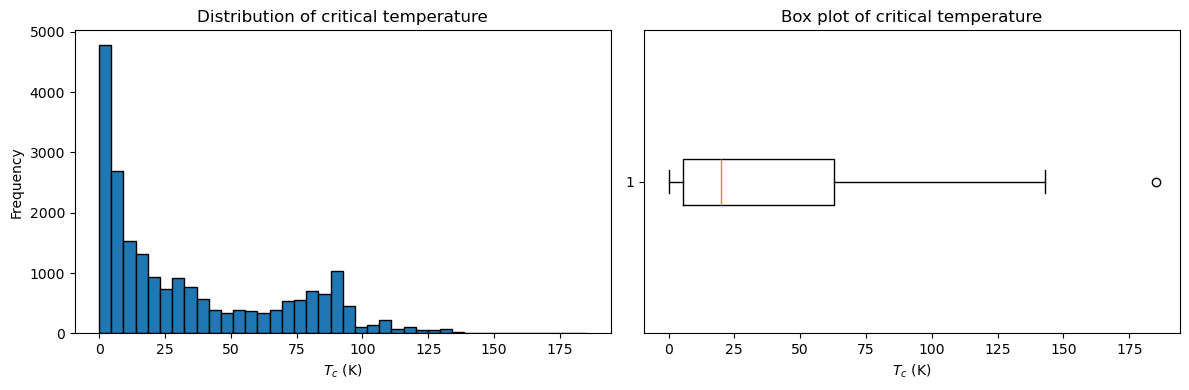

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(train["critical_temp"], bins=40, edgecolor="black")
axes[0].set_xlabel("$T_c$ (K)")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of critical temperature")

axes[1].boxplot(train["critical_temp"], vert=False)
axes[1].set_xlabel("$T_c$ (K)")
axes[1].set_title("Box plot of critical temperature")

plt.tight_layout()
plt.show()

In [9]:
correlation = train.corr()

print(correlation["critical_temp"].sort_values(ascending=False))

critical_temp                  1.000000
wtd_std_ThermalConductivity    0.721271
range_ThermalConductivity      0.687654
range_atomic_radius            0.653759
std_ThermalConductivity        0.653632
                                 ...   
gmean_Density                 -0.541684
gmean_Valence                 -0.573068
mean_Valence                  -0.600085
wtd_gmean_Valence             -0.615653
wtd_mean_Valence              -0.632401
Name: critical_temp, Length: 82, dtype: float64


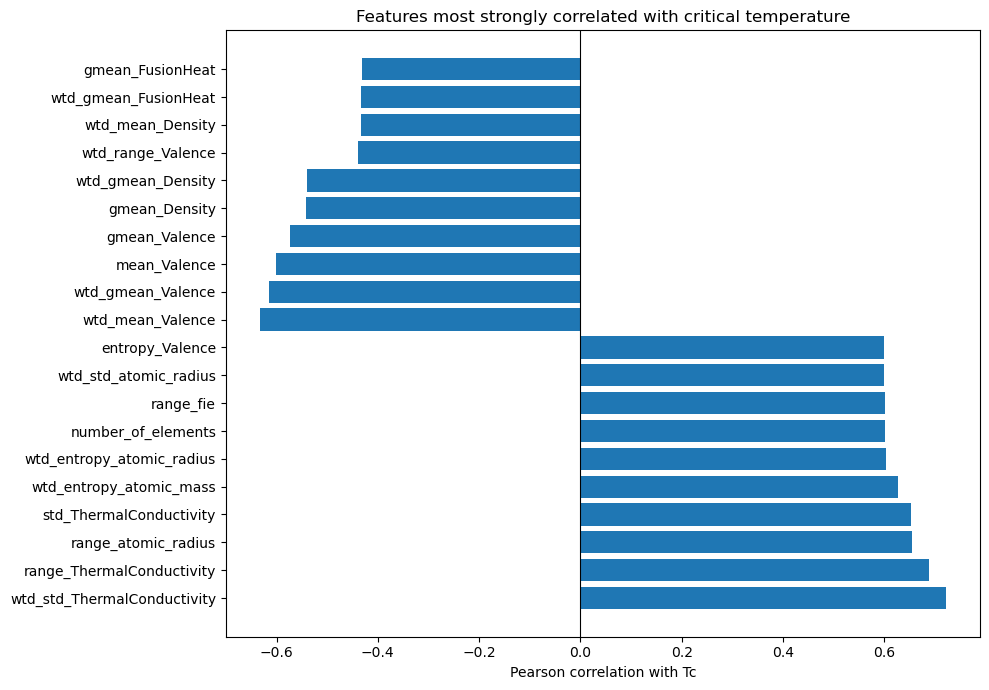

In [10]:
corr_tc = correlation["critical_temp"].drop("critical_temp")

top_corr = pd.concat([
    corr_tc.nlargest(10),
    corr_tc.nsmallest(10)
])

plt.figure(figsize=(10, 7))
plt.barh(top_corr.index, top_corr.values)
plt.xlabel("Pearson correlation with Tc")
plt.title("Features most strongly correlated with critical temperature")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [11]:
features = train.drop(columns=["critical_temp"])

feature_corr = features.corr()

print(feature_corr.abs().mean().mean())

0.3527446206118792


In [12]:
element_columns = unique_m.columns[:-2]
occurrence = (unique_m[element_columns] > 0).sum()
occurrence = occurrence.sort_values(ascending=False)

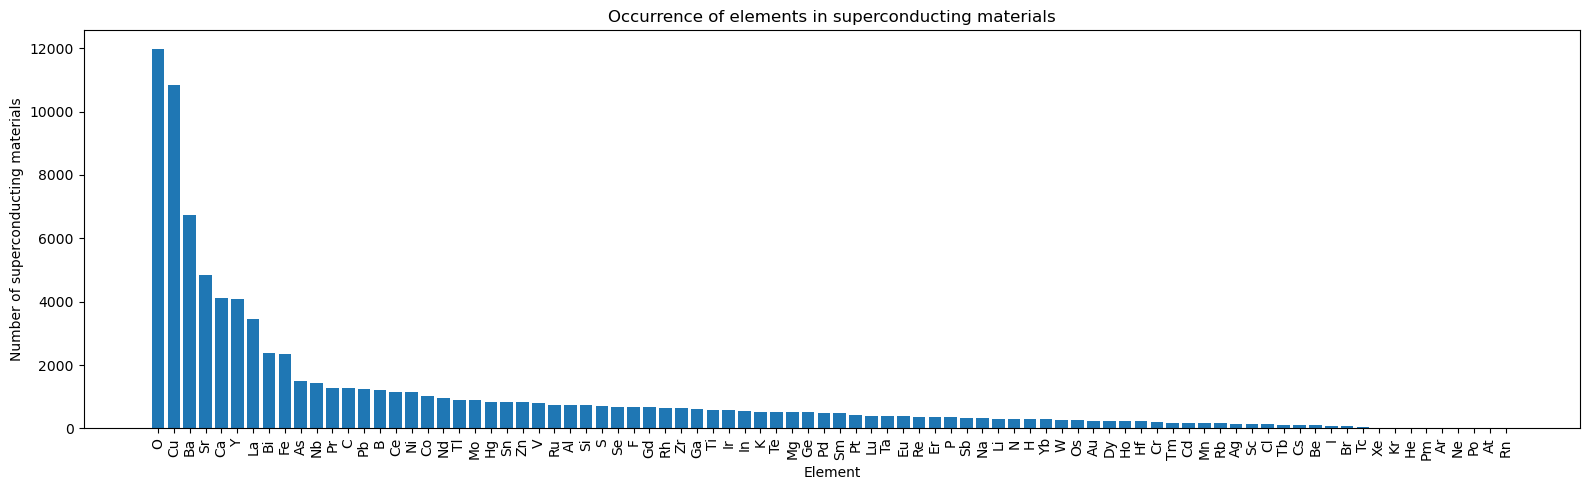

In [13]:
plt.figure(figsize=(16, 5))

plt.bar(occurrence.index, occurrence.values)

plt.xlabel("Element")
plt.ylabel("Number of superconducting materials")
plt.title("Occurrence of elements in superconducting materials")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [14]:
mean_Tc = {}

for element in element_columns:
    mask = unique_m[element] > 0
    mean_Tc[element] = unique_m.loc[mask, "critical_temp"].mean()
mean_Tc = pd.Series(mean_Tc).sort_values(ascending=False)
print(mean_Tc)

Hg    79.793539
Ca    70.003561
Tl    67.566047
Ba    64.306909
Cu    58.300128
        ...    
Xe          NaN
Pm          NaN
Po          NaN
At          NaN
Rn          NaN
Length: 86, dtype: float64


In [15]:
std_Tc = {}

for element in element_columns:
    mask = unique_m[element] > 0
    std_Tc[element] = unique_m.loc[mask, "critical_temp"].std()

std_Tc = pd.Series(std_Tc).sort_values(ascending=False)
std_Tc

Ag    42.605843
Pb    40.997282
Tl    40.668581
Hg    38.520569
Re    37.567195
        ...    
Xe          NaN
Pm          NaN
Po          NaN
At          NaN
Rn          NaN
Length: 86, dtype: float64

In [16]:
element_stats = pd.DataFrame({
    "mean_Tc": mean_Tc,
    "std_Tc": std_Tc,
    "occurrence": occurrence
})
print(element_stats)

      mean_Tc     std_Tc  occurrence
Ag  27.494627  42.605843         156
Al  17.466217  19.598023         731
Ar        NaN        NaN           0
As  21.077008  13.330804        1502
At        NaN        NaN           0
..        ...        ...         ...
Xe        NaN        NaN           0
Y   57.441268  29.793395        4075
Yb  55.126770  33.870245         291
Zn  41.041177  28.239507         832
Zr   7.174604   8.667954         631

[86 rows x 3 columns]


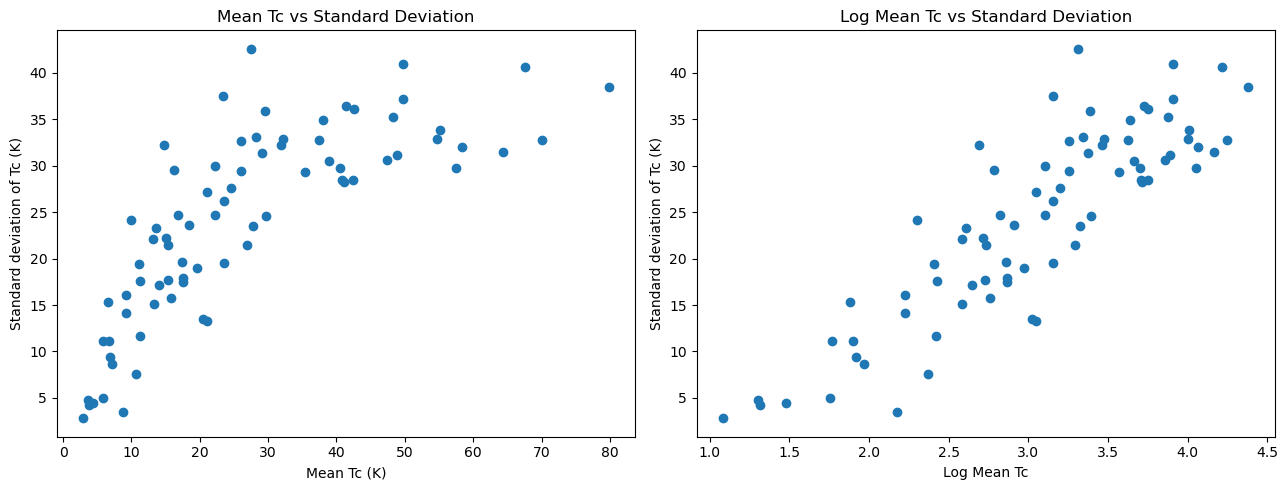

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(element_stats["mean_Tc"],
                element_stats["std_Tc"])

axes[0].set_xlabel("Mean Tc (K)")
axes[0].set_ylabel("Standard deviation of Tc (K)")
axes[0].set_title("Mean Tc vs Standard Deviation")

axes[1].scatter(np.log(element_stats["mean_Tc"]),
                element_stats["std_Tc"])

axes[1].set_xlabel("Log Mean Tc")
axes[1].set_ylabel("Standard deviation of Tc (K)")
axes[1].set_title("Log Mean Tc vs Standard Deviation")

plt.tight_layout()
plt.show()

In [18]:
train.duplicated().sum()
duplicates = train[train.duplicated(keep=False)]

print(duplicates.shape)
duplicates.head()

(131, 82)


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
360,4,76.444563,51.381751,59.356672,35.040763,1.199541,1.291294,121.3276,14.343486,43.823354,...,2.07722,2.213364,2.063611,1.368922,1.203843,1,0.841699,0.433013,0.266940,93.0
8503,4,76.444563,51.381751,59.356672,35.040763,1.199541,1.291294,121.3276,14.343486,43.823354,...,2.07722,2.213364,2.063611,1.368922,1.203843,1,0.841699,0.433013,0.266940,93.0
10567,2,60.332250,54.791708,59.596931,54.326799,0.680984,0.573959,18.7815,26.205278,9.390750,...,4.59000,3.872983,4.502887,0.661563,0.393896,2,3.360000,1.000000,0.807403,9.7
10568,2,60.332250,55.110993,59.596931,54.617434,0.680984,0.593764,18.7815,24.153981,9.390750,...,4.55600,3.872983,4.463953,0.661563,0.416027,2,3.224000,1.000000,0.831182,12.3
10569,2,60.332250,55.373934,59.596931,54.857947,0.680984,0.608434,18.7815,22.464678,9.390750,...,4.52800,3.872983,4.432142,0.661563,0.433585,2,3.112000,1.000000,0.849244,14.6


In [19]:
print("Original dataset:", train.shape)
print("After removing exact duplicates:", train.drop_duplicates().shape)

Original dataset: (21263, 82)
After removing exact duplicates: (21197, 82)


In [20]:
unique_m["material"].duplicated().sum()
print(unique_m.columns.tolist())
repeated_materials = unique_m[
    unique_m["material"].duplicated(keep=False)
].sort_values("material")

print(repeated_materials.shape)
repeated_materials.head(5)

['H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si', 'P', 'S', 'Cl', 'Ar', 'K', 'Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn', 'Ga', 'Ge', 'As', 'Se', 'Br', 'Kr', 'Rb', 'Sr', 'Y', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd', 'In', 'Sn', 'Sb', 'Te', 'I', 'Xe', 'Cs', 'Ba', 'La', 'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu', 'Hf', 'Ta', 'W', 'Re', 'Os', 'Ir', 'Pt', 'Au', 'Hg', 'Tl', 'Pb', 'Bi', 'Po', 'At', 'Rn', 'critical_temp', 'material']
(7982, 88)


,H,He,Li,Be,B,C,N,O,F,Ne,...,Au,Hg,Tl,Pb,Bi,Po,At,Rn,critical_temp,material
14278,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,6.47,Ag0.81Sn1.19Se2
17160,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,6.36,Ag0.81Sn1.19Se2
14277,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,6.23,Ag0.85Sn1.15Se2
17159,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,6.12,Ag0.85Sn1.15Se2
14275,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,5.28,Ag0.95Sn1.05Se2


In [21]:
print("Total rows:", len(unique_m))
print("Distinct formulas:", unique_m["material"].nunique())
print("Excess repeated-formula rows:",
      unique_m["material"].duplicated().sum())

Total rows: 21263
Distinct formulas: 15542
Excess repeated-formula rows: 5721


In [22]:
formula_counts = unique_m["material"].value_counts()

print("Formulas occurring more than once:",
      (formula_counts > 1).sum())

print("Maximum occurrences of one formula:",
      formula_counts.max())

Formulas occurring more than once: 2261
Maximum occurrences of one formula: 110


In [23]:
formula_stats = unique_m.groupby("material")["critical_temp"].agg(
    ["count", "min", "max", "std"]
)

repeated_stats = formula_stats[formula_stats["count"] > 1]

print("Repeated formulas with varying Tc:",
      (repeated_stats["min"] != repeated_stats["max"]).sum())

print("Repeated formulas with identical Tc:",
      (repeated_stats["min"] == repeated_stats["max"]).sum())

Repeated formulas with varying Tc: 2261
Repeated formulas with identical Tc: 0


In [24]:
print((train["critical_temp"] == unique_m["critical_temp"]).all())

True


# 2. Data Preprocessing

In [26]:
X = train.drop(columns=["critical_temp"])
y = train["critical_temp"]

print(X.shape)
print(y.shape)

(21263, 81)
(21263,)


In [27]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

In [28]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

In [29]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(14884, 81)
(3189, 81)
(3190, 81)


In [30]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

In [31]:
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [32]:
print(X_train_scaled.mean(axis=0))
print(X_train_scaled.std(axis=0))

[ 2.63040209e-16 -1.19466084e-16 -1.35935934e-16 -1.45125633e-16
 -5.57349264e-17  1.79736187e-16 -3.59949760e-16  3.81909560e-17
 -9.90577920e-17 -7.54271380e-17 -1.32713572e-16  6.50678412e-16
  4.29648255e-18 -8.42587966e-16 -7.16080424e-17 -3.65439710e-16
  5.63316601e-17 -1.56582919e-16 -3.38944734e-16  1.77587945e-16
 -1.04070355e-16 -2.56356792e-16 -5.58542731e-17 -2.63040209e-16
  6.25376904e-17 -7.78140728e-17  4.52324135e-16  7.82914597e-17
  5.20351775e-17  5.25125645e-18 -1.74484930e-16 -1.57537693e-17
 -5.17964840e-17 -1.05502516e-16  6.15829165e-17  1.98234931e-16
 -5.53768862e-17  5.57587957e-16 -1.27939702e-16 -1.20301511e-16
  4.05778907e-17 -3.82386947e-16 -2.37738701e-16 -1.01206033e-16
 -1.55150759e-16 -3.53266343e-17  2.12914580e-16 -1.71859302e-17
 -1.00251259e-16  2.13153273e-16  1.24120607e-17 -5.91959817e-17
  7.59045250e-17 -2.01457293e-16  4.91708558e-17  1.62788950e-16
 -3.29158302e-16  3.29396995e-17 -1.93341715e-17 -4.63065341e-17
  0.00000000e+00  8.85552

# 3. Model Fitting

## 3.1 Ordinary Least Squares (OLS)

In [35]:
ols_model = LinearRegression()

In [36]:
ols_model.fit(X_train, y_train)

LinearRegression()

In [37]:
ols_intercept = ols_model.intercept_
ols_coefficients = ols_model.coef_

print("Intercept:", ols_intercept)
print("Coefficient shape:", ols_coefficients.shape)

Intercept: -20.90905936154177
Coefficient shape: (81,)


In [38]:
coefficient_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": ols_coefficients
})

coefficient_table

,Feature,Coefficient
0,number_of_elements,-3.152569
1,mean_atomic_mass,0.870415
2,wtd_mean_atomic_mass,-0.924989
3,gmean_atomic_mass,-0.531806
4,wtd_gmean_atomic_mass,0.665018
...,...,...
76,wtd_entropy_Valence,-65.397983
77,range_Valence,5.296553
78,wtd_range_Valence,-0.563351
79,std_Valence,6.099029


In [39]:
y_val_pred = ols_model.predict(X_val)

In [40]:
ols_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
ols_mae = mean_absolute_error(y_val, y_val_pred)
ols_r2 = r2_score(y_val, y_val_pred)

print("OLS Validation RMSE:", ols_rmse)
print("OLS Validation MAE:", ols_mae)
print("OLS Validation R²:", ols_r2)

OLS Validation RMSE: 17.72522863847297
OLS Validation MAE: 13.580089101763777
OLS Validation R²: 0.7315672235491573


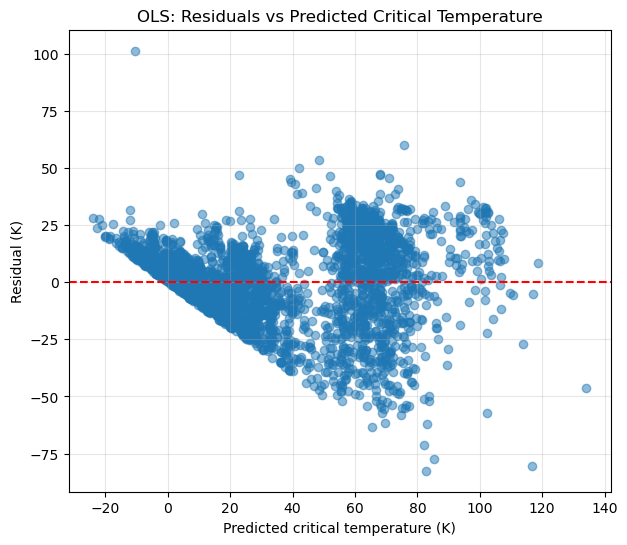

In [41]:
plt.figure(figsize=(7, 6))

plt.scatter(y_val_pred, y_val - y_val_pred, alpha=0.5)

plt.axhline(y=0, color='r', linestyle='--')

plt.xlabel('Predicted critical temperature (K)')
plt.ylabel('Residual (K)')
plt.title('OLS: Residuals vs Predicted Critical Temperature')
plt.grid(alpha=0.3)
plt.show()

## 3.2 Ridge Regression

In [43]:
alphas = np.logspace(-4, 4, 50)

In [44]:
val_rmse = []

for alpha in alphas:
    ridge_model = Ridge(alpha=alpha)
    ridge_model.fit(X_train_scaled, y_train)

    y_val_pred = ridge_model.predict(X_val_scaled)

    rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
    val_rmse.append(rmse)

In [45]:
best_idx = np.argmin(val_rmse)

best_alpha = alphas[best_idx]
best_rmse = val_rmse[best_idx]

print("Best alpha:", best_alpha)
print("Best validation RMSE:", best_rmse)

Best alpha: 0.0001
Best validation RMSE: 17.725231381500837


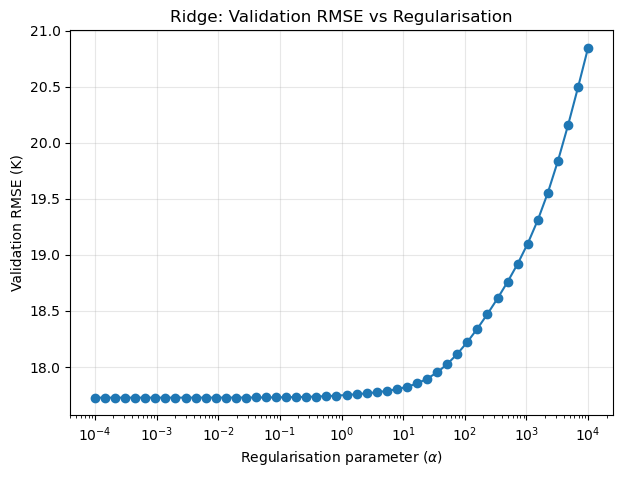

In [46]:
plt.figure(figsize=(7, 5))
plt.plot(alphas, val_rmse, marker='o')
plt.xscale('log')
plt.xlabel(r'Regularisation parameter ($\alpha$)')
plt.ylabel('Validation RMSE (K)')
plt.title('Ridge: Validation RMSE vs Regularisation')
plt.grid(alpha=0.3)
plt.show()

## 3.3 XGBoost Regression

### 3.3.1 Baseline XGBoost Model

In [51]:
baseline_model = XGBRegressor(
    objective='reg:squarederror',
    n_estimators=750,
    learning_rate=0.02,
    max_depth=16,
    min_child_weight=1,
    colsample_bytree=0.5,
    subsample=0.5,
    random_state=42,
    n_jobs=-1
)

baseline_model.fit(X_train, y_train)

baseline_results = []

for n_trees in range(1, 751):

    y_pred = baseline_model.predict(
        X_val,
        iteration_range=(0, n_trees)
    )

    rmse = np.sqrt(mean_squared_error(y_val, y_pred))

    baseline_results.append((n_trees, rmse))

best_tree, best_rmse = min(
    baseline_results, key=lambda x: x[1]
)

In [84]:
print("Optimal number of trees:", best_tree)
print("Minimum validation RMSE:", best_rmse)

Optimal number of trees: 360
Minimum validation RMSE: 8.628490188149623


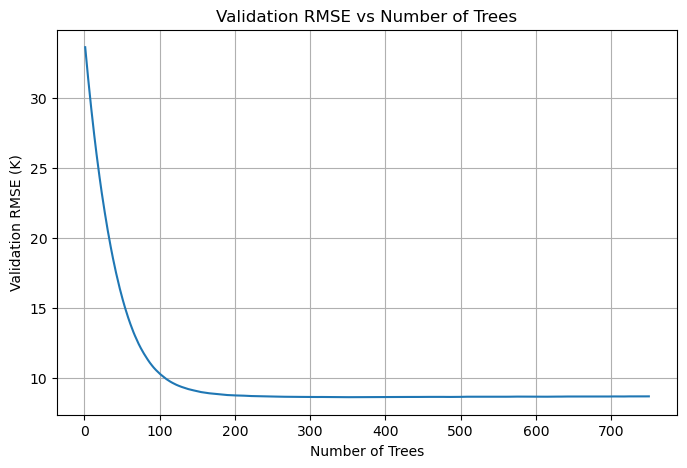

In [53]:
trees = [result[0] for result in baseline_results]
rmse = [result[1] for result in baseline_results]

plt.figure(figsize=(8, 5))

plt.plot(trees, rmse)

plt.xlabel("Number of Trees")
plt.ylabel("Validation RMSE (K)")
plt.title("Validation RMSE vs Number of Trees")

plt.grid()
plt.show()

### 3.3.2 Hyperparameter Tuning

In [55]:
param_grid = {
    'learning_rate': [0.010, 0.015, 0.020],
    'max_depth': list(range(15, 26)),
    'min_child_weight': [1, 10],
    'colsample_bytree': [0.25, 0.50, 0.75]
}

In [56]:
random_configs = list(ParameterSampler(
    param_grid,
    n_iter=50,
    random_state=42
))

print("Number of configurations:", len(random_configs))

for i, config in enumerate(random_configs):
    print(i + 1, config)

Number of configurations: 50
1 {'min_child_weight': 10, 'max_depth': 25, 'learning_rate': 0.02, 'colsample_bytree': 0.25}
2 {'min_child_weight': 1, 'max_depth': 17, 'learning_rate': 0.02, 'colsample_bytree': 0.5}
3 {'min_child_weight': 1, 'max_depth': 23, 'learning_rate': 0.01, 'colsample_bytree': 0.25}
4 {'min_child_weight': 10, 'max_depth': 19, 'learning_rate': 0.01, 'colsample_bytree': 0.75}
5 {'min_child_weight': 1, 'max_depth': 16, 'learning_rate': 0.015, 'colsample_bytree': 0.75}
6 {'min_child_weight': 1, 'max_depth': 23, 'learning_rate': 0.02, 'colsample_bytree': 0.5}
7 {'min_child_weight': 1, 'max_depth': 19, 'learning_rate': 0.01, 'colsample_bytree': 0.75}
8 {'min_child_weight': 1, 'max_depth': 19, 'learning_rate': 0.015, 'colsample_bytree': 0.25}
9 {'min_child_weight': 1, 'max_depth': 24, 'learning_rate': 0.01, 'colsample_bytree': 0.25}
10 {'min_child_weight': 10, 'max_depth': 21, 'learning_rate': 0.015, 'colsample_bytree': 0.75}
11 {'min_child_weight': 1, 'max_depth': 17, 'l

In [57]:
results = []

for i, params in enumerate(random_configs):

    model = XGBRegressor(
        objective='reg:squarederror',
        n_estimators=750,
        subsample=0.5,
        random_state=42,
        n_jobs=-1,
        **params
    )

    model.fit(X_train, y_train)

    for n_trees in range(1, 751):

        y_pred = model.predict(
            X_val,
            iteration_range=(0, n_trees)
        )

        rmse = np.sqrt(mean_squared_error(y_val, y_pred))

        results.append({
            'configuration': i + 1,
            **params,
            'n_trees': n_trees,
            'RMSE': rmse
        })

    print(f"Completed configuration {i+1}/50")

Completed configuration 1/50
Completed configuration 2/50
Completed configuration 3/50
Completed configuration 4/50
Completed configuration 5/50
Completed configuration 6/50
Completed configuration 7/50
Completed configuration 8/50
Completed configuration 9/50
Completed configuration 10/50
Completed configuration 11/50
Completed configuration 12/50
Completed configuration 13/50
Completed configuration 14/50
Completed configuration 15/50
Completed configuration 16/50
Completed configuration 17/50
Completed configuration 18/50
Completed configuration 19/50
Completed configuration 20/50
Completed configuration 21/50
Completed configuration 22/50
Completed configuration 23/50
Completed configuration 24/50
Completed configuration 25/50
Completed configuration 26/50
Completed configuration 27/50
Completed configuration 28/50
Completed configuration 29/50
Completed configuration 30/50
Completed configuration 31/50
Completed configuration 32/50
Completed configuration 33/50
Completed configura

In [58]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='RMSE'
).reset_index(drop=True)

print(results_df.head(10))

   configuration  min_child_weight  max_depth  learning_rate  \
0             29                10         18           0.02   
1             29                10         18           0.02   
2             29                10         18           0.02   
3             29                10         18           0.02   
4             29                10         18           0.02   
5             29                10         18           0.02   
6             29                10         18           0.02   
7             29                10         18           0.02   
8             29                10         18           0.02   
9             33                10         22           0.02   

   colsample_bytree  n_trees      RMSE  
0               0.5      750  8.572162  
1               0.5      748  8.573132  
2               0.5      749  8.573172  
3               0.5      710  8.573343  
4               0.5      713  8.573377  
5               0.5      717  8.573378  
6       

In [59]:
best_per_config = (
    results_df
    .sort_values('RMSE')
    .groupby('configuration')
    .first()
    .sort_values('RMSE')
)

print(best_per_config.head(1))

               min_child_weight  max_depth  learning_rate  colsample_bytree  \
configuration                                                                 
29                           10         18           0.02               0.5   

               n_trees      RMSE  
configuration                     
29                 750  8.572162  


In [60]:
top_configs = best_per_config.head(5)

extended_results = []

for config_id, params in top_configs.iterrows():

    model = XGBRegressor(
        objective='reg:squarederror',
        eval_metric='rmse',
        n_estimators=1500,
        subsample=0.5,
        random_state=42,
        n_jobs=-1,
        min_child_weight=int(params['min_child_weight']),
        max_depth=int(params['max_depth']),
        learning_rate=params['learning_rate'],
        colsample_bytree=params['colsample_bytree']
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    rmse_values = model.evals_result()['validation_0']['rmse']

    for n_trees, rmse in enumerate(rmse_values, start=1):

        extended_results.append({
            'configuration': config_id,
            'n_trees': n_trees,
            'RMSE': float(rmse)
        })

    print(f"Completed configuration {config_id}")

Completed configuration 29
Completed configuration 33
Completed configuration 48
Completed configuration 27
Completed configuration 28


In [62]:
extended_df = pd.DataFrame(extended_results)

best_extended = (
    extended_df
    .sort_values('RMSE')
    .groupby('configuration')
    .first()
    .sort_values('RMSE')
)

In [64]:
best_configuration_id = int(best_extended.index[0])
best_n_estimators = int(best_extended.iloc[0]['n_trees'])
best_validation_rmse = best_extended.iloc[0]['RMSE']

best_params = random_configs[best_configuration_id - 1]

print("Best configuration:", best_configuration_id)
print("Best parameters:", best_params)
print("Optimal number of trees:", best_n_estimators)
print("Best validation RMSE:", best_validation_rmse)

Best configuration: 28
Best parameters: {'min_child_weight': 10, 'max_depth': 19, 'learning_rate': 0.015, 'colsample_bytree': 0.75}
Optimal number of trees: 1069
Best validation RMSE: 8.549840858886473


### 3.3.3 Final Model Training and Test Evaluation

In [66]:
X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

In [68]:
final_model = XGBRegressor(
    objective='reg:squarederror',
    n_estimators=best_n_estimators,
    learning_rate=best_params['learning_rate'],
    max_depth=best_params['max_depth'],
    min_child_weight=best_params['min_child_weight'],
    colsample_bytree=best_params['colsample_bytree'],
    subsample=0.5,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_trainval, y_trainval)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.75, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.015, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=19,
             max_leaves=None, min_child_weight=10, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1069,
             n_jobs=-1, num_parallel_tree=None, ...)

In [72]:
y_pred = final_model.predict(X_test)

In [74]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Test RMSE:", rmse)
print("Test MAE:", mae)
print("Test R²:", r2)

Test RMSE: 9.560473622626935
Test MAE: 5.10963203863662
Test R²: 0.9205842151447128


In [76]:
ols_model = LinearRegression()
ols_model.fit(X_trainval, y_trainval)

y_pred_ols = ols_model.predict(X_test)

ols_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ols))
ols_mae = mean_absolute_error(y_test, y_pred_ols)
ols_r2 = r2_score(y_test, y_pred_ols)

print("OLS Test RMSE:", ols_rmse)
print("OLS Test MAE:", ols_mae)
print("OLS Test R²:", ols_r2)

OLS Test RMSE: 17.773293004083744
OLS Test MAE: 13.26687769457652
OLS Test R²: 0.7255369922977732


In [78]:
comparison = pd.DataFrame({
    'Model': ['OLS', 'XGBoost'],
    'Test RMSE (K)': [ols_rmse, rmse],
    'Test MAE (K)': [ols_mae, mae],
    'Test R²': [ols_r2, r2]
})

print(comparison)

     Model  Test RMSE (K)  Test MAE (K)   Test R²
0      OLS      17.773293     13.266878  0.725537
1  XGBoost       9.560474      5.109632  0.920584


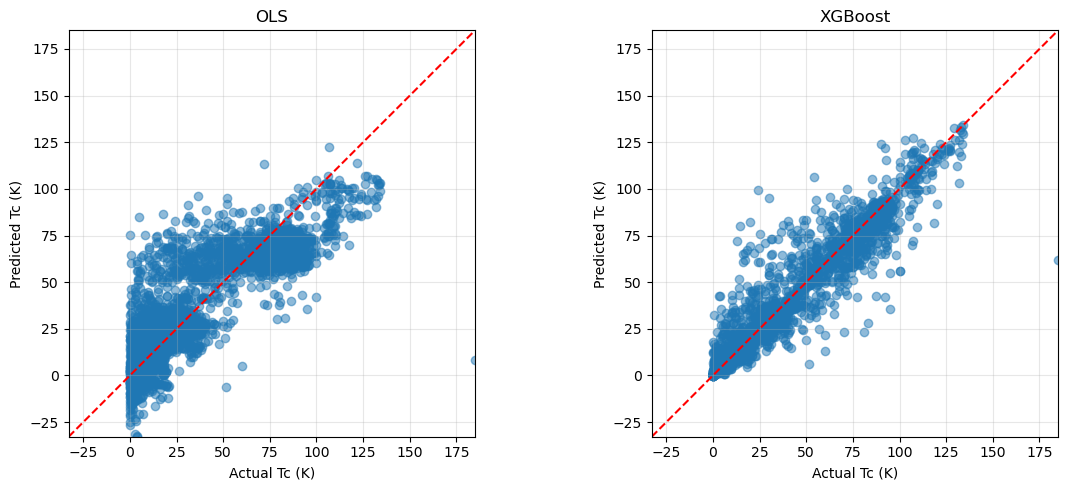

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, y_pred_ols, alpha=0.5)
axes[0].set_title('OLS')
axes[0].set_xlabel('Actual Tc (K)')
axes[0].set_ylabel('Predicted Tc (K)')

axes[1].scatter(y_test, y_pred, alpha=0.5)
axes[1].set_title('XGBoost')
axes[1].set_xlabel('Actual Tc (K)')
axes[1].set_ylabel('Predicted Tc (K)')

lower = min(y_test.min(), y_pred_ols.min(), y_pred.min())
upper = max(y_test.max(), y_pred_ols.max(), y_pred.max())

for ax in axes:
    ax.plot([lower, upper], [lower, upper], 'r--')
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

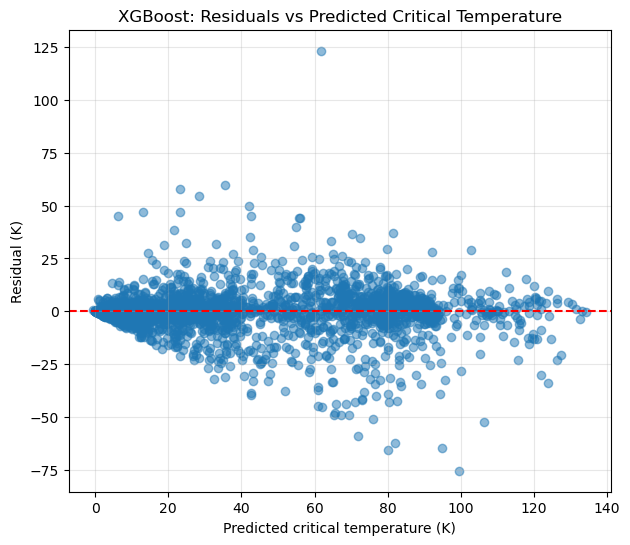

In [82]:
xgb_residuals = y_test - y_pred

plt.figure(figsize=(7, 6))
plt.scatter(y_pred, xgb_residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')

plt.xlabel('Predicted critical temperature (K)')
plt.ylabel('Residual (K)')
plt.title('XGBoost: Residuals vs Predicted Critical Temperature')
plt.grid(alpha=0.3)
plt.show()